# Task 2 - Tank Battle: Adversarial Search

Runs a smaller version of `run_experiments.py`. The GUI is started with `python main.py`.

In [1]:
from tank_battle.maps import BUILTIN_MAPS
from tank_battle.search import SearchConfig, AdversarialSearch
from tank_battle.agents import SearchAgent, RandomAgent
from tank_battle.session import HeadlessMatch
from tank_battle.rules import GameRules
from tank_battle.experiments import FixedDepthExperiment, FixedTimeExperiment, machine_description
print(machine_description())
print('maps:', list(BUILTIN_MAPS))

Linux-6.18.44-fc-v470-x86_64-with-glibc2.39 | x86_64 x86_64 | Python 3.13.18
maps: ['Crossroads', 'Fortress', 'Corridors', 'Bunkers', 'Duel', 'Islands', 'Diagonal']


## Requirement 1 - the game as a zero-sum game

State, actions, transition `GameRules.step`, terminal test `GameRules.outcome` and utility (+1 / -1 / 0).

In [2]:
state = BUILTIN_MAPS['Duel'].create_state()
print('actions:', [a.name for a in GameRules.legal_actions(state, 0)])
print('tanks:', state.tanks)
print('bases:', state.bases)
nxt = GameRules.step(state, 4, 5)  # P1 fires, P2 stays
print('bullets after one cycle:', nxt.bullets)
print('terminal?', GameRules.outcome(nxt))

actions: ['MOVE_UP', 'MOVE_DOWN', 'MOVE_LEFT', 'MOVE_RIGHT', 'FIRE', 'STAY']
tanks: (Tank(owner=0, x=5, y=4, facing=0, hp=6), Tank(owner=1, x=1, y=2, facing=1, hp=6))
bases: (Base(owner=0, x=3, y=6, hp=9), Base(owner=1, x=3, y=0, hp=9))
bullets after one cycle: (Bullet(owner=0, x=5, y=1, direction=0),)
terminal? None


## Requirement 2 - the four configurations at the same depth

Pruned and unpruned versions must return the same value and action (the experiment raises an error otherwise).

In [3]:
fixed_depth = FixedDepthExperiment(depths=(1, 2, 3), repeats=1).run()
cols = fixed_depth.columns
import statistics
summary = {}
for row in fixed_depth.rows:
    key = (row[cols.index('depth_cycles')], row[cols.index('configuration')])
    summary.setdefault(key, []).append((row[cols.index('time_ms')], row[cols.index('nodes')]))
print(f"{'depth':>5} {'configuration':<22} {'mean ms':>9} {'mean nodes':>11}")
for (d, name), vals in sorted(summary.items()):
    print(f'{d:>5} {name:<22} {statistics.mean(v[0] for v in vals):9.2f} {statistics.mean(v[1] for v in vals):11.0f}')

depth configuration            mean ms  mean nodes
    1 Alpha-Beta                  0.04          18
    1 Heuristic Alpha-Beta        0.71          21
    1 Heuristic Minimax           1.08          43
    1 Minimax                     0.12          43
    2 Alpha-Beta                  0.25         130
    2 Heuristic Alpha-Beta        3.11         225
    2 Heuristic Minimax          14.13        1555
    2 Minimax                     3.90        1555
    3 Alpha-Beta                  1.70         812
    3 Heuristic Alpha-Beta       14.99        2095
    3 Heuristic Minimax         328.20       55655
    3 Minimax                   135.32       55655


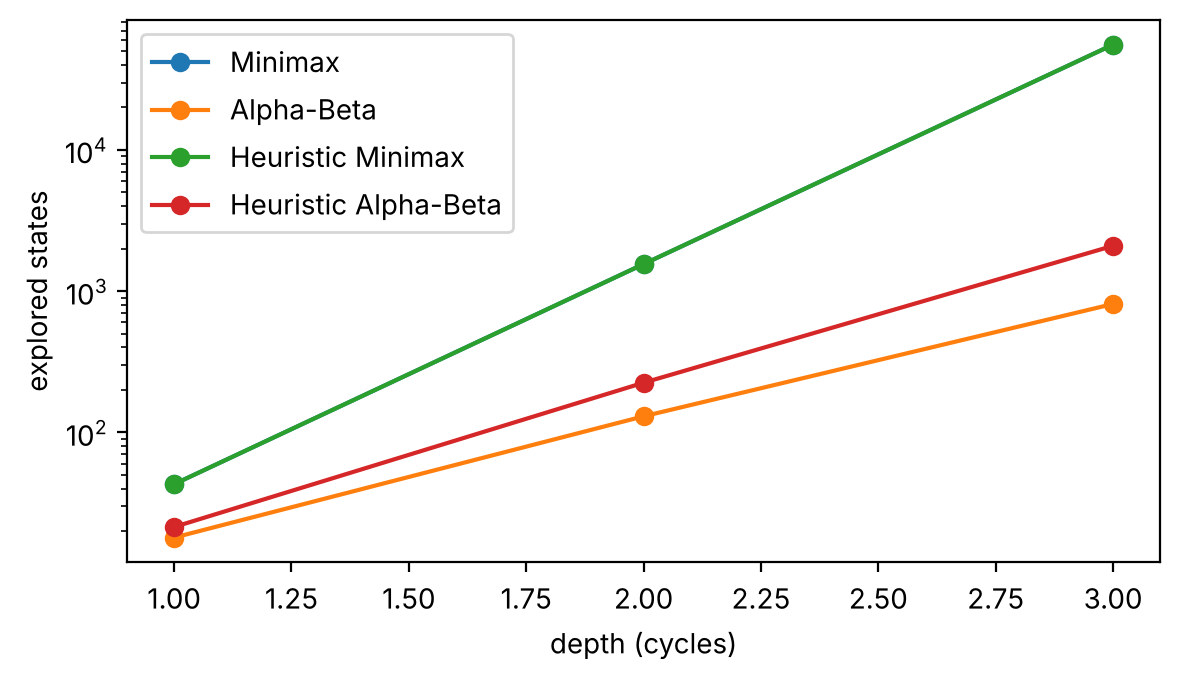

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ['Minimax', 'Alpha-Beta', 'Heuristic Minimax', 'Heuristic Alpha-Beta']:
    ds = sorted(d for d, n in summary if n == name)
    ax.plot(ds, [statistics.mean(v[1] for v in summary[(d, name)]) for d in ds], 'o-', label=name)
ax.set_yscale('log'); ax.set_xlabel('depth (cycles)'); ax.set_ylabel('explored states'); ax.legend(); plt.tight_layout(); plt.show()

### Same time per decision (iterative deepening)

In [5]:
print(FixedTimeExperiment(limits=(0.05, 0.2), repeats=1).run())

time_limit_ms |                 configuration | median_depth_cycles | mean_depth_cycles | max_depth_cycles | mean_nodes | mean_nodes_per_ms | mean_table_hits
--------------+-------------------------------+---------------------+-------------------+------------------+------------+-------------------+----------------
        50.00 |                       Minimax |                2.00 |                 2 |                2 |   20275.20 |            403.75 |               0
        50.00 |                    Alpha-Beta |                4.00 |                 4 |                4 |   26803.20 |            532.51 |               0
        50.00 |             Heuristic Minimax |                2.00 |                 2 |                2 |    7321.60 |            143.32 |               0
        50.00 |          Heuristic Alpha-Beta |                3.00 |              3.10 |                4 |       9856 |            192.26 |               0
        50.00 | Heuristic A-B + optimizations |     

### One full game without the GUI

In [6]:
agents = (SearchAgent(SearchConfig.optimized(), time_limit=0.05, seed=0), RandomAgent(0))
res = HeadlessMatch(BUILTIN_MAPS['Bunkers'].create_state(), agents, 0.05).play()
print('outcome:', res.outcome, '(0 = optimized agent wins)', 'cycles:', res.cycles)

outcome: 0 (0 = optimized agent wins) cycles: 15
